# Saudi Arabia Urban Air Quality — End-to-End Machine Learning
### Exploratory Data Analysis, Source Classification & Pollutant Regression

**Dataset:** [Air Quality Dataset — Kaggle](https://www.kaggle.com/datasets/srisyra02/air-quality-dataset)

**Author:** [Mobeen Fatima](https://www.kaggle.com/mobeenfatimah) ML Engineer

This notebook builds a complete, CPU-friendly supervised machine-learning workflow using timestamped pollutant, sensor and meteorological measurements.

**Workflow:** data acquisition → inspection → cleaning → EDA → visualization → feature engineering → source classification → pollutant regression → evaluation → feature importance → model export.

**Interpretation:** `Source` labels are described as manually assigned. Classification scores measure agreement with those labels, not proof of physical pollution sources. Regression predicts an observed pollutant measurement, not a regulatory or causal outcome. Sensor datasets often use `-200` for missing readings; this notebook converts it to missing data. Time-based holdouts are used when timestamps are sufficiently available. No deep-learning frameworks are required.

In [1]:
import os, glob, zipfile, io, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42
TEST_SIZE = 0.20
print("Libraries ready.")

Libraries ready.


## 1. Import machine-learning tools

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, mean_absolute_error, mean_squared_error, r2_score)
import joblib
print("Scikit-learn imported.")

Scikit-learn imported.


## 2. Configure dataset and targets

In [3]:
DATASET_SLUG = "srisyra02/air-quality-dataset"
TARGET_CLASS = "Source"
PREFERRED_REGRESSION_TARGETS = ["NO2(GT)", "NOx(GT)", "CO(GT)", "C6H6(GT)"]
print("Dataset:", DATASET_SLUG)

Dataset: srisyra02/air-quality-dataset


## 3. Find local CSV files

In [4]:
roots = [Path("."), Path("/kaggle/input")]
csv_files = []
for root in roots:
    if root.exists():
        csv_files += [Path(p) for p in glob.glob(str(root / "**" / "*.csv"), recursive=True)]
csv_files = list(dict.fromkeys(csv_files))
print("CSV files:", [str(p) for p in csv_files[:20]])

CSV files: ['/kaggle/input/datasets/srisyra02/air-quality-dataset/air_quality_dataset.csv']


## 4. Download dataset from Kaggle if needed

In [5]:
if not csv_files:
    try:
        import requests
        url = f"https://www.kaggle.com/api/v1/datasets/download/{DATASET_SLUG}"
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(response.content)) as z:
            names = [n for n in z.namelist() if n.lower().endswith(".csv")]
            if not names: raise FileNotFoundError("No CSV found in archive.")
            for name in names:
                Path(Path(name).name).write_bytes(z.read(name))
        csv_files = [Path(p) for p in glob.glob("*.csv")]
        print("Downloaded:", [p.name for p in csv_files])
    except Exception as exc:
        print("Download failed:", type(exc).__name__, str(exc)[:200])
        print("Manually download the Kaggle CSV and place it beside this notebook.")

## 5. Load the selected CSV

In [6]:
if not csv_files:
    raise FileNotFoundError("No CSV found. Download the Kaggle dataset and place its CSV beside this notebook.")
preferred = [p for p in csv_files if "air" in p.name.lower() or "quality" in p.name.lower()]
DATA_PATH = preferred[0] if preferred else csv_files[0]

raw = pd.read_csv(
    DATA_PATH,
    sep=None,
    engine="python",
    decimal=","
)
df = raw.copy()
print("File:", DATA_PATH, "| Shape:", df.shape)
display(df.head())

File: /kaggle/input/datasets/srisyra02/air-quality-dataset/air_quality_dataset.csv | Shape: (500, 10)


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835


## 6. Standardize column names

In [7]:
df.columns = [str(c).strip() for c in df.columns]
print(df.columns.tolist())

['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature']


## 7. Inspect schema and sample

In [8]:
display(df.dtypes.astype(str).to_frame("dtype"))
display(df.sample(min(5, len(df)), random_state=RANDOM_STATE))

,dtype
PM2.5,float64
PM10,float64
NOx,float64
NO2,float64
SO2,float64
VOCs,float64
CO,float64
CO2,float64
CH4,float64
Temperature,float64


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
361,26.548982,67.391718,25.540563,15.565702,7.273767,49.813578,1.344661,386.943809,2.126732,25.905401
73,35.961208,53.065871,89.137594,36.908279,5.444268,70.425028,2.627878,411.053927,1.762626,29.120538
374,34.236104,57.787207,92.240780,33.988519,5.530397,67.073694,2.088690,399.001268,1.680025,32.196658
155,84.233115,134.931202,138.620102,52.919981,13.431673,132.622343,2.333705,493.927666,2.892274,32.245444
104,57.061711,65.457159,33.406000,22.175908,9.128806,108.888766,0.826086,380.662778,2.209384,29.709851


## 8. Normalize missing tokens and numeric columns

In [9]:
df = df.replace(["", "?", "NA", "N/A", "null", "None", "nan"], np.nan)
for col in df.columns:
    if col.lower() not in ["date", "time", "source"]:
        converted = pd.to_numeric(df[col], errors="coerce")
        if converted.notna().sum() >= max(3, int(0.5 * df[col].notna().sum())):
            df[col] = converted
print("Numeric conversion complete.")

Numeric conversion complete.


## 9. Replace common -200 missing-value sentinel

In [10]:
num0 = df.select_dtypes(include=np.number).columns
sentinel_counts = {c:int((df[c] == -200).sum()) for c in num0 if (df[c] == -200).any()}
display(pd.Series(sentinel_counts, name="sentinel_count").to_frame())
for c in num0: df.loc[df[c] == -200, c] = np.nan

,sentinel_count


## 10. Parse Date and Time

In [11]:
date_col = next((c for c in df.columns if c.lower() == "date"), None)
time_col = next((c for c in df.columns if c.lower() == "time"), None)
df["timestamp"] = pd.NaT
if date_col:
    dtext = df[date_col].astype(str).str.strip()
    parsed = pd.to_datetime(dtext, errors="coerce", dayfirst=True)
    if time_col:
        ttext = df[time_col].astype(str).str.strip().str.replace(".", ":", regex=False)
        parsed_full = pd.to_datetime(dtext + " " + ttext, errors="coerce", dayfirst=True)
        df["timestamp"] = parsed_full.fillna(parsed)
    else: df["timestamp"] = parsed
print("Timestamp coverage:", round(df.timestamp.notna().mean()*100, 1), "%")

Timestamp coverage: 0.0 %


## 11. Sort data and inspect duplicates

In [12]:
print("Exact duplicate rows:", int(df.duplicated().sum()))
if df.timestamp.notna().any(): df = df.sort_values("timestamp").reset_index(drop=True)
print("Sorted shape:", df.shape)

Exact duplicate rows: 0
Sorted shape: (500, 11)


## 12. Missing-value audit

In [13]:
missing = pd.DataFrame({"count":df.isna().sum(), "percent":df.isna().mean()*100})
display(missing.sort_values("percent", ascending=False).round(2))

,count,percent
timestamp,500,100.0
PM10,0,0.0
PM2.5,0,0.0
NOx,0,0.0
NO2,0,0.0
VOCs,0,0.0
SO2,0,0.0
CO,0,0.0
CO2,0,0.0
CH4,0,0.0


## 13. Visualize missingness

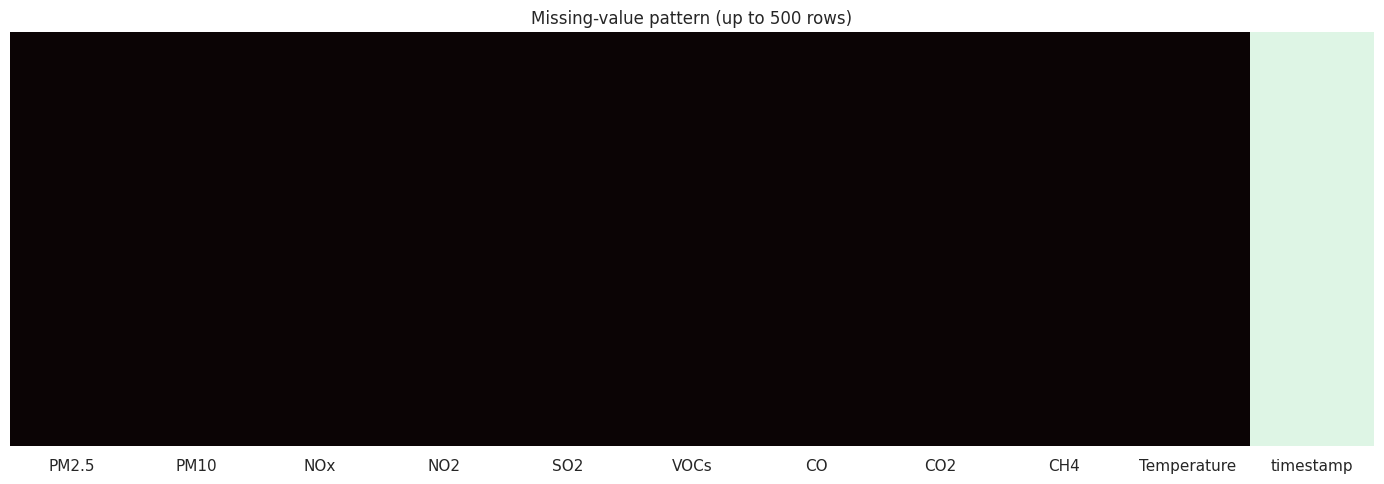

In [14]:
sample_missing = df.sample(min(500, len(df)), random_state=RANDOM_STATE) if len(df)>500 else df
plt.figure(figsize=(14,5))
sns.heatmap(sample_missing.isna(), cbar=False, yticklabels=False, cmap="mako")
plt.title("Missing-value pattern (up to 500 rows)")
plt.tight_layout(); plt.show()

## 14. Identify numeric measurement features

In [15]:
TARGET_CLASS_PRESENT = TARGET_CLASS in df.columns
exclude = {TARGET_CLASS, "timestamp"}
if date_col: exclude.add(date_col)
if time_col: exclude.add(time_col)
numeric_features = [c for c in df.select_dtypes(include=np.number).columns if c not in exclude]
print("Numeric features:", len(numeric_features), numeric_features)

Numeric features: 10 ['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature']


## 15. Descriptive statistics

In [16]:
if not numeric_features: raise ValueError("No numeric columns detected; inspect CSV delimiter and decimal format.")
display(df[numeric_features].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
PM2.5,500.0,54.67,22.80,10.76,36.37,48.04,73.82,127.62
PM10,500.0,84.70,30.57,12.93,61.12,78.14,110.27,171.59
NOx,500.0,91.81,54.81,-0.08,35.46,95.45,134.71,225.89
NO2,500.0,42.41,26.34,-1.94,17.45,39.21,63.82,115.92
SO2,500.0,11.50,7.31,-1.10,5.98,8.68,17.12,31.94
VOCs,500.0,112.19,39.47,27.56,81.52,104.82,140.59,231.93
CO,500.0,2.18,0.82,0.37,1.54,2.05,2.73,4.80
CO2,500.0,439.29,51.22,366.06,397.40,420.93,490.97,558.92
CH4,500.0,2.13,0.39,1.39,1.84,2.07,2.39,3.35
Temperature,500.0,30.45,2.96,19.58,28.48,30.43,32.61,39.78


## 16. Plot pollutant distributions

In [17]:
pollutant_names = ["CO(GT)","NMHC(GT)","C6H6(GT)","NOx(GT)","NO2(GT)","O3(GT)"]
pollutants = [c for c in pollutant_names if c in df and pd.api.types.is_numeric_dtype(df[c])]
if pollutants:
    fig, axes = plt.subplots(len(pollutants), 1, figsize=(10, 2.6*len(pollutants)))
    axes = np.atleast_1d(axes)
    for ax,c in zip(axes,pollutants):
        sns.histplot(df[c].dropna(), bins=35, kde=True, ax=ax)
        ax.set_title(f"Distribution of {c}")
    plt.tight_layout(); plt.show()
else: print("Standard pollutant names not found; inspect numeric feature list.")

Standard pollutant names not found; inspect numeric feature list.


## 17. Compare pollutant ranges with boxplots

In [18]:
if pollutants:
    fig, axes = plt.subplots(len(pollutants), 1, figsize=(10, 2.2*len(pollutants)))
    axes = np.atleast_1d(axes)
    for ax,c in zip(axes,pollutants):
        sns.boxplot(x=df[c], ax=ax, color="#75aadb")
        ax.set_title(c)
    plt.tight_layout(); plt.show()

## 18. Explore meteorological variables

In [19]:
weather = [c for c in ["T","RH","AH"] if c in df and pd.api.types.is_numeric_dtype(df[c])]
if weather:
    fig, axes = plt.subplots(1, len(weather), figsize=(5*len(weather),3.5))
    axes = np.atleast_1d(axes)
    for ax,c in zip(axes,weather):
        sns.histplot(df[c].dropna(), bins=30, ax=ax)
        ax.set_title(f"{c} distribution")
    plt.tight_layout(); plt.show()
else: print("Standard weather columns not found.")

Standard weather columns not found.


## 19. Numeric correlation heatmap

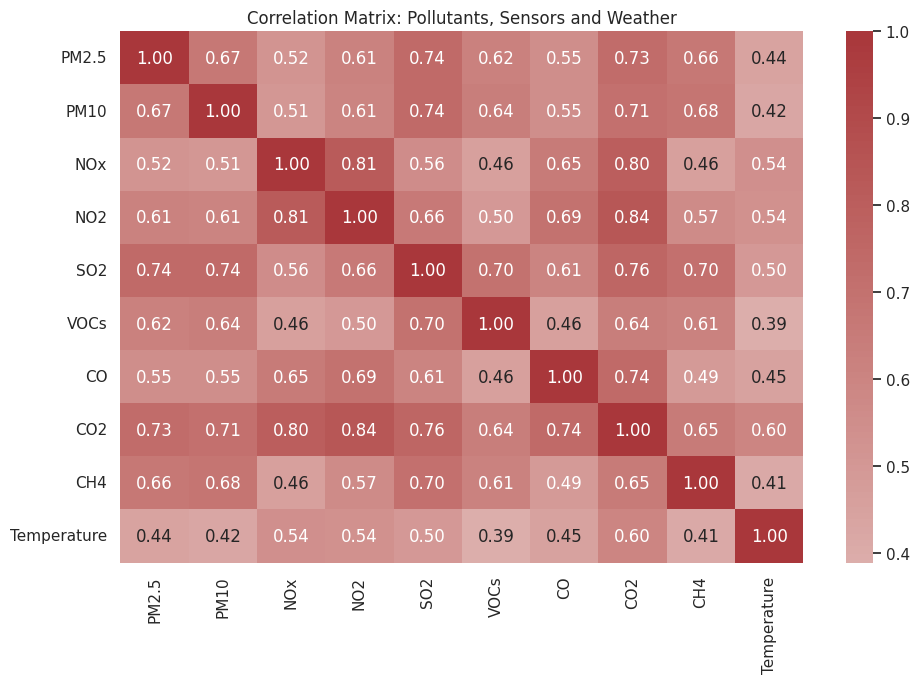

In [20]:
corr = df[numeric_features].corr(numeric_only=True)
plt.figure(figsize=(max(10,.7*len(corr)), max(7,.65*len(corr))))
sns.heatmap(corr, cmap="vlag", center=0, annot=len(corr)<=12, fmt=".2f")
plt.title("Correlation Matrix: Pollutants, Sensors and Weather")
plt.tight_layout(); plt.show()

## 20. Rank correlated feature pairs

In [21]:
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().rename("correlation").to_frame()
pairs["abs_corr"] = pairs.correlation.abs()
display(pairs.sort_values("abs_corr", ascending=False).head(15).round(3))

correlation  abs_corr
NO2   CO2         0.837     0.837
NOx   NO2         0.813     0.813
      CO2         0.801     0.801
SO2   CO2         0.762     0.762
PM2.5 SO2         0.740     0.740
CO    CO2         0.738     0.738
PM10  SO2         0.737     0.737
PM2.5 CO2         0.731     0.731
PM10  CO2         0.709     0.709
SO2   CH4         0.704     0.704
      VOCs        0.704     0.704
NO2   CO          0.695     0.695
PM10  CH4         0.682     0.682
PM2.5 PM10        0.670     0.670
      CH4         0.664     0.664

## 21. Inspect source class distribution

In [22]:
print("Available columns:")
for col in df.columns:
    print(col)

Available columns:
PM2.5
PM10
NOx
NO2
SO2
VOCs
CO
CO2
CH4
Temperature
timestamp


In [23]:
if not TARGET_CLASS_PRESENT:
    print(f"'{TARGET_CLASS}' not found in dataset.")
else:
    df[TARGET_CLASS] = pd.to_numeric(df[TARGET_CLASS], errors="coerce")

    print("Target Variable:", TARGET_CLASS)
    print("\nTarget Statistics:")

    display(df[TARGET_CLASS].describe().to_frame("PM2.5 Statistics"))

    print("\nMissing Values:", df[TARGET_CLASS].isna().sum())

'Source' not found in dataset.


## 22. Visualize source class balance

In [24]:
TARGET_CLASS = "PM2.5"
TARGET_CLASS_PRESENT = TARGET_CLASS in df.columns

print("Target:", TARGET_CLASS)
print("Available:", TARGET_CLASS_PRESENT)

Target: PM2.5
Available: True


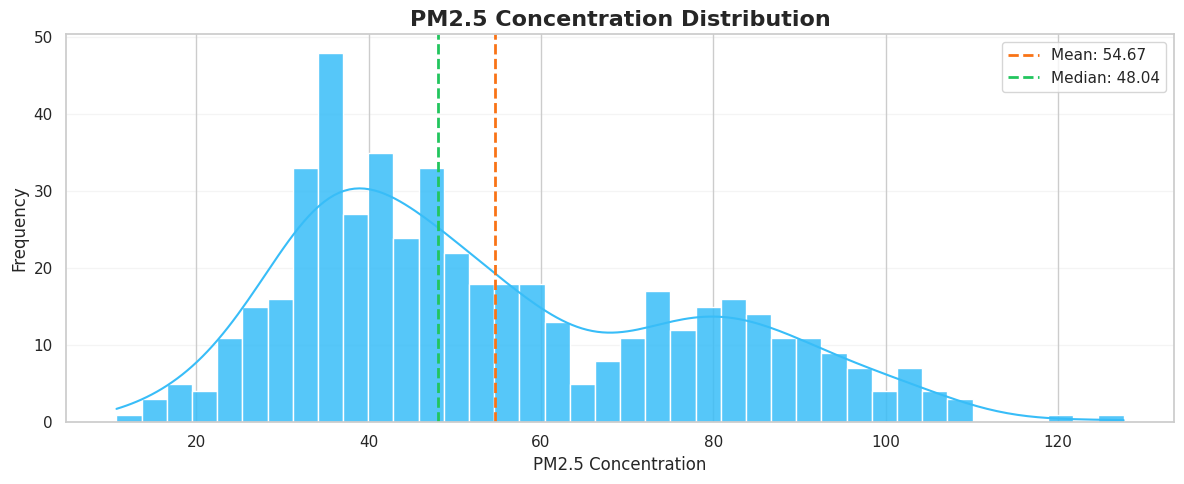

In [25]:
# PM2.5 Distribution Analysis

plot_data = pd.to_numeric(df["PM2.5"], errors="coerce").dropna()

plt.figure(figsize=(12, 5))

sns.histplot(
    plot_data,
    bins=40,
    kde=True,
    color="#38bdf8",
    edgecolor="white",
    alpha=0.85
)

plt.axvline(
    plot_data.mean(),
    color="#f97316",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {plot_data.mean():.2f}"
)

plt.axvline(
    plot_data.median(),
    color="#22c55e",
    linestyle="--",
    linewidth=2,
    label=f"Median: {plot_data.median():.2f}"
)

plt.title("PM2.5 Concentration Distribution", fontsize=16, fontweight="bold")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("Frequency")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 23. Compare pollutant distributions by source

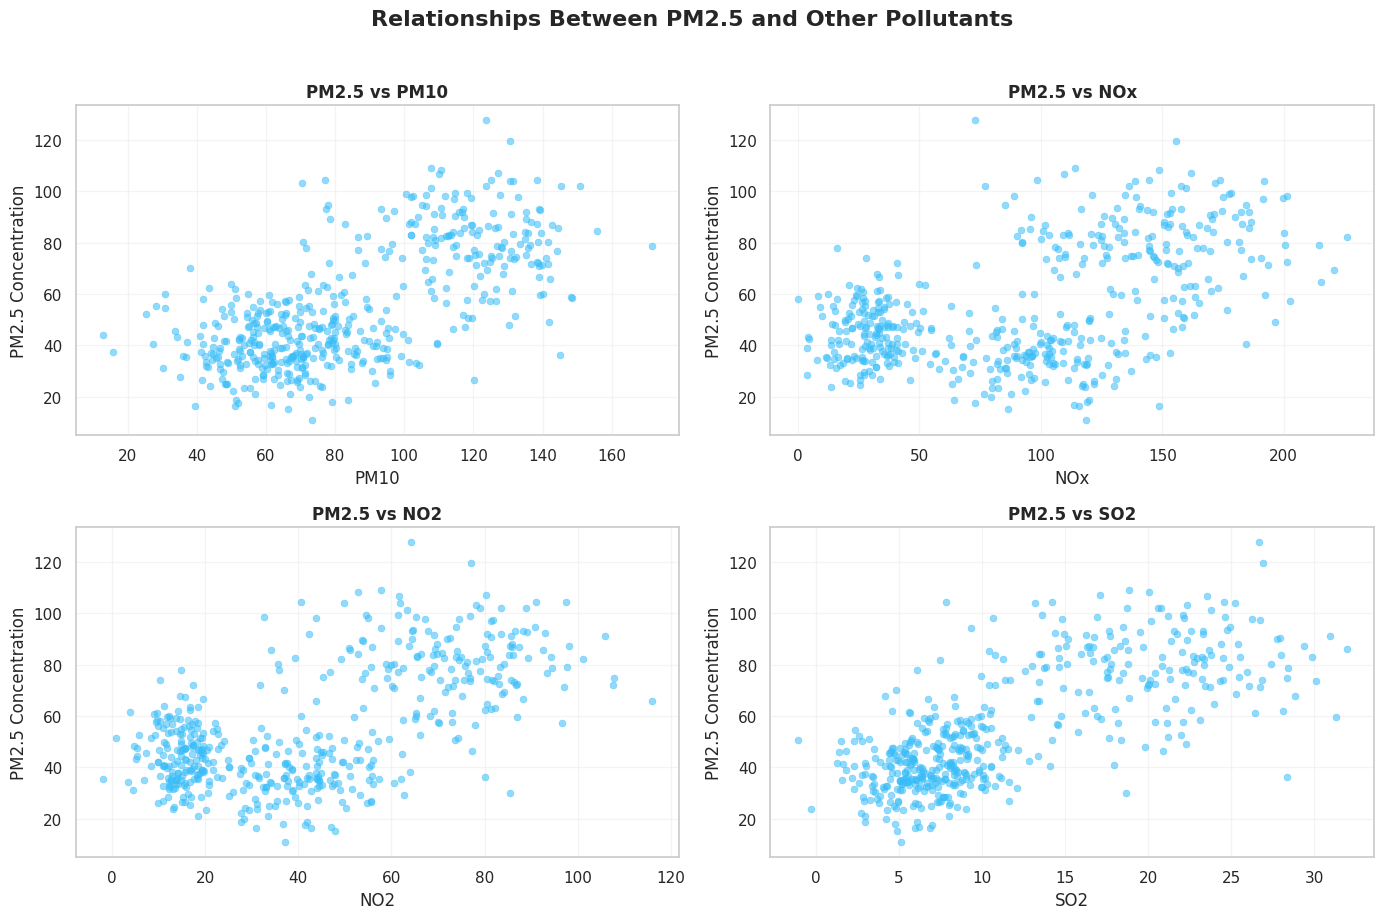

In [26]:
# PM2.5 vs Other Pollutants

pollutants = ["PM10", "NOx", "NO2", "SO2", "VOCs", "CO", "CO2", "CH4"]
chosen = [c for c in pollutants if c in df.columns][:4]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, col in zip(axes, chosen):

    sns.scatterplot(
        data=df,
        x=col,
        y="PM2.5",
        ax=ax,
        color="#38bdf8",
        alpha=0.55,
        s=25,
        edgecolor=None
    )

    ax.set_title(f"PM2.5 vs {col}", fontsize=12, fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("PM2.5 Concentration")
    ax.grid(alpha=0.2)

for ax in axes[len(chosen):]:
    ax.set_visible(False)

plt.suptitle(
    "Relationships Between PM2.5 and Other Pollutants",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

## 24. Engineer calendar features

In [27]:
# Convert timestamp to datetime
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

# Check timestamp availability
if df["timestamp"].notna().mean() >= 0.5:

    # Extract calendar features
    df["hour"] = df["timestamp"].dt.hour
    df["day"] = df["timestamp"].dt.day
    df["month"] = df["timestamp"].dt.month
    df["year"] = df["timestamp"].dt.year
    df["day_of_week"] = df["timestamp"].dt.dayofweek

    # Weekend indicator
    df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

    # Additional time features
    df["quarter"] = df["timestamp"].dt.quarter

    print("Calendar features created successfully.")

    display(
        df[[
            "timestamp", "hour", "day", "month",
            "year", "day_of_week", "is_weekend", "quarter"
        ]].head()
    )

else:
    print("Insufficient valid timestamps; calendar features skipped.")

Insufficient valid timestamps; calendar features skipped.


## 25. Visualize hourly and monthly pollutant patterns

In [28]:
# Select an available pollutant
pollutant_options = ["PM2.5", "PM10", "NO2", "NOx", "SO2", "CO"]

time_target = next(
    (col for col in pollutant_options if col in df.columns),
    None
)

if time_target and "timestamp" in df.columns:

    # Ensure valid datetime and numerical values
    temp_df = df[["timestamp", time_target]].copy()
    temp_df["timestamp"] = pd.to_datetime(temp_df["timestamp"], errors="coerce")
    temp_df[time_target] = pd.to_numeric(temp_df[time_target], errors="coerce")
    temp_df = temp_df.dropna()

    if not temp_df.empty:

        temp_df["hour"] = temp_df["timestamp"].dt.hour
        temp_df["month"] = temp_df["timestamp"].dt.month

        fig, axes = plt.subplots(1, 2, figsize=(15, 5))

        # Hourly pollution trend
        hourly = temp_df.groupby("hour")[time_target].mean()

        axes[0].plot(
            hourly.index,
            hourly.values,
            marker="o",
            linewidth=2,
            color="#38bdf8"
        )

        axes[0].fill_between(
            hourly.index,
            hourly.values,
            alpha=0.15,
            color="#38bdf8"
        )

        axes[0].set_title(f"Average {time_target} by Hour", fontweight="bold")
        axes[0].set_xlabel("Hour of Day")
        axes[0].set_ylabel("Average Concentration")
        axes[0].set_xticks(range(0, 24, 2))
        axes[0].grid(alpha=0.2)

        # Monthly pollution trend
        monthly = temp_df.groupby("month")[time_target].mean()

        axes[1].plot(
            monthly.index,
            monthly.values,
            marker="o",
            linewidth=2,
            color="#f97316"
        )

        axes[1].fill_between(
            monthly.index,
            monthly.values,
            alpha=0.15,
            color="#f97316"
        )

        axes[1].set_title(f"Average {time_target} by Month", fontweight="bold")
        axes[1].set_xlabel("Month")
        axes[1].set_ylabel("Average Concentration")
        axes[1].set_xticks(range(1, 13))
        axes[1].grid(alpha=0.2)

        plt.suptitle(
            "Temporal Air Pollution Analysis",
            fontsize=16,
            fontweight="bold"
        )

        plt.tight_layout()
        plt.show()

    else:
        print("No valid temporal pollution records available.")

else:
    print("Required pollutant or timestamp column is unavailable.")

No valid temporal pollution records available.


## 26. Prepare classification features and labels

In [29]:
# Prepare Regression Dataset

TARGET_COL = "PM2.5"

if TARGET_COL not in df.columns:
    raise ValueError(f"Required regression target '{TARGET_COL}' is missing.")

# Keep rows with valid target values
reg_df = df[df[TARGET_COL].notna()].copy()

# Select numerical features
reg_features = [
    c for c in reg_df.select_dtypes(include=np.number).columns
    if c != TARGET_COL
]

# Prepare X and y
X_reg = reg_df[reg_features].replace([np.inf, -np.inf], np.nan)
y_reg = pd.to_numeric(reg_df[TARGET_COL], errors="coerce")

# Remove invalid target values
valid_idx = y_reg.notna()
X_reg = X_reg.loc[valid_idx]
y_reg = y_reg.loc[valid_idx]

print("Regression Dataset Prepared Successfully")
print("-" * 45)
print("Rows:", len(X_reg))
print("Features:", len(reg_features))
print("Target:", TARGET_COL)
print("Task Type: Regression")
print("Target Mean:", round(y_reg.mean(), 2))
print("Target Median:", round(y_reg.median(), 2))

display(X_reg.head())

Regression Dataset Prepared Successfully
---------------------------------------------
Rows: 500
Features: 9
Target: PM2.5
Task Type: Regression
Target Mean: 54.67
Target Median: 48.04


,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835


## 27. Split classification data chronologically when possible

In [30]:
# Train-Test Split for Regression

if reg_df["timestamp"].notna().mean() >= 0.5:

    # Chronological split to prevent future-data leakage
    idx = reg_df.loc[X_reg.index].sort_values("timestamp").index

    cut = max(1, int(len(idx) * (1 - TEST_SIZE)))

    tr_idx, te_idx = idx[:cut], idx[cut:]

    X_train_reg, X_test_reg = X_reg.loc[tr_idx], X_reg.loc[te_idx]
    y_train_reg, y_test_reg = y_reg.loc[tr_idx], y_reg.loc[te_idx]

    reg_split = "chronological holdout"

else:

    # Random split when timestamps are unavailable
    X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
        X_reg,
        y_reg,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE
    )

    reg_split = "random holdout"

print("Split Strategy:", reg_split)
print("Training Shape:", X_train_reg.shape)
print("Testing Shape:", X_test_reg.shape)
print("Training Target Mean:", round(y_train_reg.mean(), 2))
print("Testing Target Mean:", round(y_test_reg.mean(), 2))

Split Strategy: random holdout
Training Shape: (400, 9)
Testing Shape: (100, 9)
Training Target Mean: 54.14
Testing Target Mean: 56.81


## 28. Build a dummy classification baseline

In [31]:
# Regression Baseline Model

pre_reg = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), reg_features)
])

dummy_reg = Pipeline([
    ("prep", pre_reg),
    ("model", DummyRegressor(strategy="mean"))
])

# Train baseline model
dummy_reg.fit(X_train_reg, y_train_reg)

# Generate predictions
dummy_pred = dummy_reg.predict(X_test_reg)

# Evaluate baseline
print("Baseline MAE:", mean_absolute_error(y_test_reg, dummy_pred))
print("Baseline MSE:", mean_squared_error(y_test_reg, dummy_pred))
print("Baseline RMSE:", np.sqrt(mean_squared_error(y_test_reg, dummy_pred)))
print("Baseline R2 Score:", r2_score(y_test_reg, dummy_pred))

Baseline MAE: 19.825004583829998
Baseline MSE: 573.5438139195655
Baseline RMSE: 23.948774789528702
Baseline R2 Score: -0.012638642855443027


## 29. Train Random Forest classifier

In [32]:
# Random Forest Regression Model

rf_reg = Pipeline([
    ("prep", ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), reg_features)
    ])),
    ("model", RandomForestRegressor(
        n_estimators=160,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Train model
rf_reg.fit(X_train_reg, y_train_reg)

# Generate predictions
rf_pred = rf_reg.predict(X_test_reg)

print("Random Forest Regressor trained successfully.")

Random Forest Regressor trained successfully.


## 30. Train Extra Trees classifier

In [33]:
# Extra Trees Regression Model
from sklearn.ensemble import ExtraTreesRegressor
et_reg = Pipeline([
    ("prep", ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), reg_features)
    ])),
    ("model", ExtraTreesRegressor(
        n_estimators=160,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Train model
et_reg.fit(X_train_reg, y_train_reg)

# Generate predictions
et_pred = et_reg.predict(X_test_reg)

print("Extra Trees Regressor trained successfully.")

Extra Trees Regressor trained successfully.


## 31. Compare classification models

In [34]:
# Compare Regression Models

reg_results = []

for name, pred in [
    ("Dummy baseline", dummy_pred),
    ("Random Forest", rf_pred),
    ("Extra Trees", et_pred)
]:
    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_reg, pred),
        "MSE": mean_squared_error(y_test_reg, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, pred)),
        "R2 Score": r2_score(y_test_reg, pred)
    })

# Create comparison table
reg_scores = pd.DataFrame(reg_results).sort_values(
    "RMSE", ascending=True
)

display(reg_scores.round(4))

# Select the best model based on lowest RMSE
best_reg_name = reg_scores.iloc[0]["Model"]

best_reg = {
    "Random Forest": rf_reg,
    "Extra Trees": et_reg
}.get(best_reg_name, dummy_reg)

best_reg_pred = best_reg.predict(X_test_reg)

print("Best Model:", best_reg_name)
print("Best RMSE:", round(reg_scores.iloc[0]["RMSE"], 4))
print("Best R2 Score:", round(r2_score(y_test_reg, best_reg_pred), 4))

,Model,MAE,MSE,RMSE,R2 Score
2,Extra Trees,10.7004,194.2413,13.9370,0.6571
1,Random Forest,10.8614,196.2070,14.0074,0.6536
0,Dummy baseline,19.8250,573.5438,23.9488,-0.0126


Best Model: Extra Trees
Best RMSE: 13.937
Best R2 Score: 0.6571


## 32. Detailed classification report

In [35]:
# Final Regression Model Evaluation

print("Selected Model:", best_reg_name)
print("-" * 45)

print("MAE:", round(mean_absolute_error(y_test_reg, best_reg_pred), 4))
print("MSE:", round(mean_squared_error(y_test_reg, best_reg_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_reg, best_reg_pred)), 4))
print("R2 Score:", round(r2_score(y_test_reg, best_reg_pred), 4))

Selected Model: Extra Trees
---------------------------------------------
MAE: 10.7004
MSE: 194.2413
RMSE: 13.937
R2 Score: 0.6571


## 33. Confusion matrix visualization

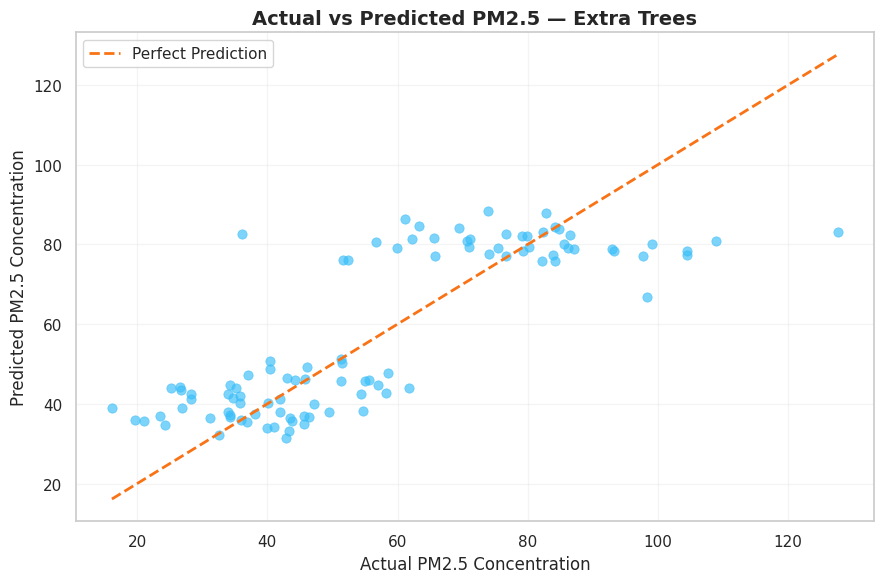

In [36]:
# Actual vs Predicted PM2.5 Values

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_test_reg,
    y=best_reg_pred,
    color="#38bdf8",
    alpha=0.65,
    s=45,
    edgecolor=None
)

# Perfect prediction reference line
min_val = min(y_test_reg.min(), best_reg_pred.min())
max_val = max(y_test_reg.max(), best_reg_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    color="#f97316",
    linewidth=2,
    label="Perfect Prediction"
)

plt.title(f"Actual vs Predicted PM2.5 — {best_reg_name}",
          fontsize=14, fontweight="bold")
plt.xlabel("Actual PM2.5 Concentration")
plt.ylabel("Predicted PM2.5 Concentration")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 34. Classification feature importance

,Importance
CO2,0.3538
SO2,0.1780
NO2,0.1106
PM10,0.1029
CH4,0.0947
NOx,0.0532
VOCs,0.0516
CO,0.0298
Temperature,0.0255


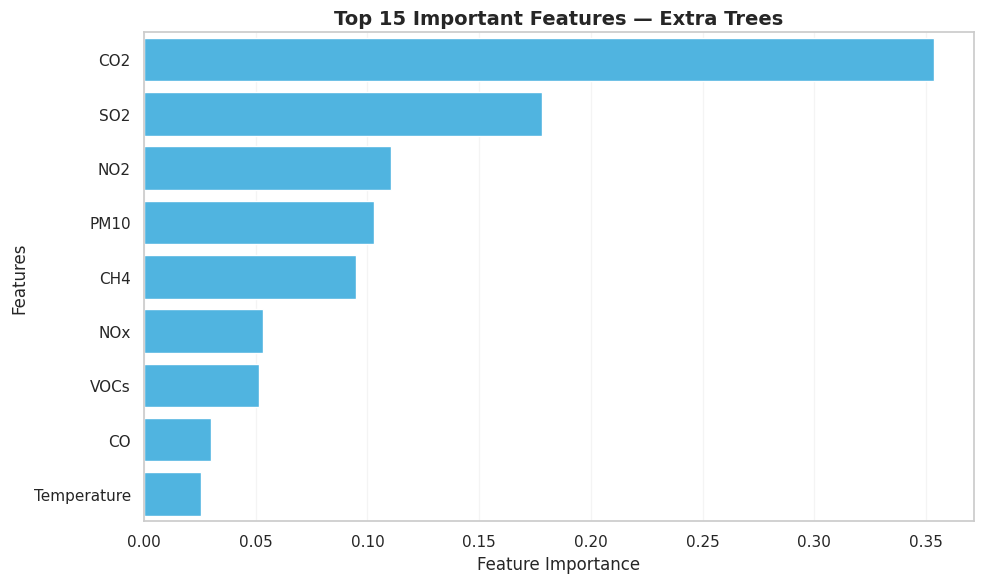

In [37]:
# Regression Feature Importance Analysis

reg_tree = best_reg.named_steps["model"]

if hasattr(reg_tree, "feature_importances_"):

    imp = pd.Series(
        reg_tree.feature_importances_,
        index=reg_features
    ).sort_values(ascending=False).head(15)

    display(imp.to_frame("Importance").round(4))

    plt.figure(figsize=(10, 6))

    sns.barplot(
        x=imp.values,
        y=imp.index,
        color="#38bdf8"
    )

    plt.title(
        f"Top 15 Important Features — {best_reg_name}",
        fontsize=14,
        fontweight="bold"
    )
    plt.xlabel("Feature Importance")
    plt.ylabel("Features")
    plt.grid(axis="x", alpha=0.2)
    plt.tight_layout()
    plt.show()

else:
    print("Feature importance is not available for the selected model.")

## 35. Select a pollutant regression target

In [38]:
# Define Regression Target

TARGET_COL = "PM2.5"

if TARGET_COL not in df.columns:
    raise ValueError(f"Regression target '{TARGET_COL}' is missing from the dataset.")

if not pd.api.types.is_numeric_dtype(df[TARGET_COL]):
    df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")

reg_target = TARGET_COL

print(
    "Regression target:", reg_target,
    "| Valid rows:", int(df[reg_target].notna().sum())
)
print("Task type: Regression")

Regression target: PM2.5 | Valid rows: 500
Task type: Regression


## 36. Prepare regression data and split

In [39]:
# Prepare Regression Dataset

reg_df = df[df[reg_target].notna()].copy()

# Select numerical features, excluding target and raw timestamp
reg_features = [
    c for c in reg_df.select_dtypes(include=np.number).columns
    if c not in [reg_target, "timestamp"]
]

# Prepare features and target
X_reg = reg_df[reg_features].replace([np.inf, -np.inf], np.nan)
y_reg = pd.to_numeric(reg_df[reg_target], errors="coerce")

# Remove invalid target values
valid_idx = y_reg.notna()
X_reg = X_reg.loc[valid_idx]
y_reg = y_reg.loc[valid_idx]
reg_df = reg_df.loc[valid_idx]

# Chronological or random train-test split
if "timestamp" in reg_df.columns:

    timestamps = pd.to_datetime(reg_df["timestamp"], errors="coerce")

else:
    timestamps = pd.Series(pd.NaT, index=reg_df.index)

if timestamps.notna().mean() >= 0.5:

    ridx = timestamps.sort_values().index

    cut = max(1, int(len(ridx) * (1 - TEST_SIZE)))
    cut = min(cut, len(ridx) - 1)

    tri, tei = ridx[:cut], ridx[cut:]

    X_train_reg, X_test_reg = X_reg.loc[tri], X_reg.loc[tei]
    y_train_reg, y_test_reg = y_reg.loc[tri], y_reg.loc[tei]

    reg_split = "chronological holdout"

else:

    X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
        X_reg,
        y_reg,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE
    )

    reg_split = "random holdout"

print("Split Strategy:", reg_split)
print("Training Samples:", len(X_train_reg))
print("Testing Samples:", len(X_test_reg))
print("Features:", len(reg_features))
print("Target:", reg_target)

Split Strategy: random holdout
Training Samples: 400
Testing Samples: 100
Features: 9
Target: PM2.5


## 37. Train baseline and ensemble regression models

In [40]:
# Regression Model Pipeline

def make_reg_pipeline(model):
    return Pipeline([
        ("prep", ColumnTransformer([
            ("num", SimpleImputer(strategy="median"), reg_features)
        ])),
        ("model", model)
    ])


# Initialize regression models
dummy_reg = make_reg_pipeline(
    DummyRegressor(strategy="mean")
)

rf_reg = make_reg_pipeline(
    RandomForestRegressor(
        n_estimators=140,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
)

et_reg = make_reg_pipeline(
    ExtraTreesRegressor(
        n_estimators=140,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
)


# Train all models
models = {
    "Dummy Regressor": dummy_reg,
    "Random Forest Regressor": rf_reg,
    "Extra Trees Regressor": et_reg
}

for name, model in models.items():
    model.fit(X_train_reg, y_train_reg)
    print(f"{name} trained successfully.")

print("\nAll regression models are ready.")

Dummy Regressor trained successfully.
Random Forest Regressor trained successfully.
Extra Trees Regressor trained successfully.

All regression models are ready.


## 38. Evaluate regression models

In [41]:
# Compare Regression Model Performance

reg_models = {
    "Mean Baseline": dummy_reg,
    "Random Forest": rf_reg,
    "Extra Trees": et_reg
}

reg_rows = []

for name, model in reg_models.items():

    pred = model.predict(X_test_reg)

    reg_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_reg, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, pred)),
        "R2 Score": r2_score(y_test_reg, pred)
    })

# Create model comparison table
reg_scores = pd.DataFrame(reg_rows).sort_values(
    "RMSE", ascending=True
).reset_index(drop=True)

display(reg_scores.round(4))

# Select best-performing model
best_reg_name = reg_scores.iloc[0]["Model"]
best_reg = reg_models[best_reg_name]

# Generate final predictions
best_reg_pred = best_reg.predict(X_test_reg)

print("=" * 45)
print("Best Regression Model:", best_reg_name)
print("MAE:", round(mean_absolute_error(y_test_reg, best_reg_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_reg, best_reg_pred)), 4))
print("R2 Score:", round(r2_score(y_test_reg, best_reg_pred), 4))
print("=" * 45)

,Model,MAE,RMSE,R2 Score
0,Extra Trees,10.7357,13.9450,0.6567
1,Random Forest,10.8726,14.0510,0.6514
2,Mean Baseline,19.8250,23.9488,-0.0126


Best Regression Model: Extra Trees
MAE: 10.7357
RMSE: 13.945
R2 Score: 0.6567


## 39. Plot actual vs predicted pollutant values

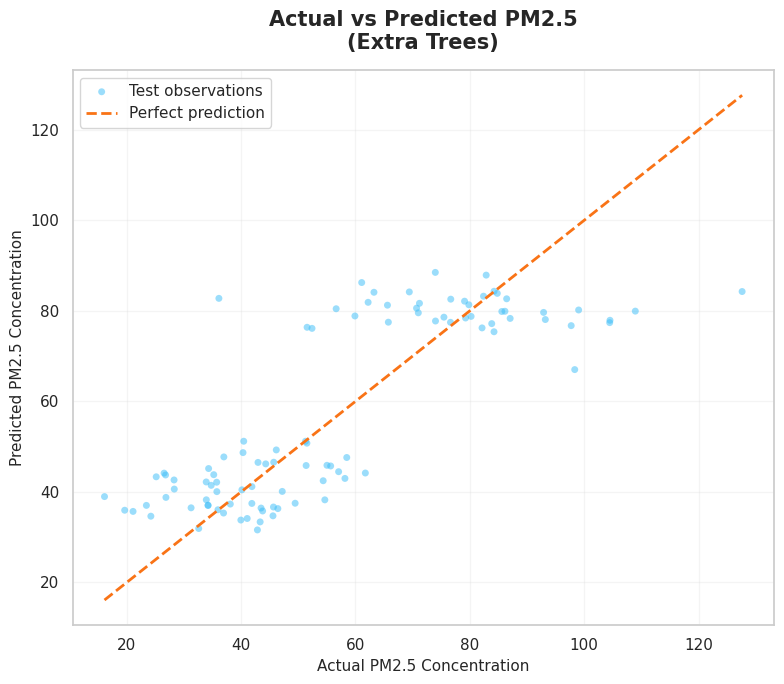

In [42]:
# Actual vs Predicted PM2.5 Concentration

n = min(2000, len(y_test_reg))

rng = np.random.default_rng(RANDOM_STATE)

ix = (
    rng.choice(len(y_test_reg), n, replace=False)
    if len(y_test_reg) > n
    else np.arange(len(y_test_reg))
)

actual = np.asarray(y_test_reg)[ix]
predicted = np.asarray(best_reg_pred)[ix]

lo = min(actual.min(), predicted.min())
hi = max(actual.max(), predicted.max())

plt.figure(figsize=(8, 7))

plt.scatter(
    actual,
    predicted,
    alpha=0.5,
    s=25,
    color="#38bdf8",
    edgecolors="none",
    label="Test observations"
)

# Perfect prediction reference line
plt.plot(
    [lo, hi],
    [lo, hi],
    color="#f97316",
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

plt.title(
    f"Actual vs Predicted {reg_target}\n({best_reg_name})",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel(f"Actual {reg_target} Concentration", fontsize=11)
plt.ylabel(f"Predicted {reg_target} Concentration", fontsize=11)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 40. Residual analysis

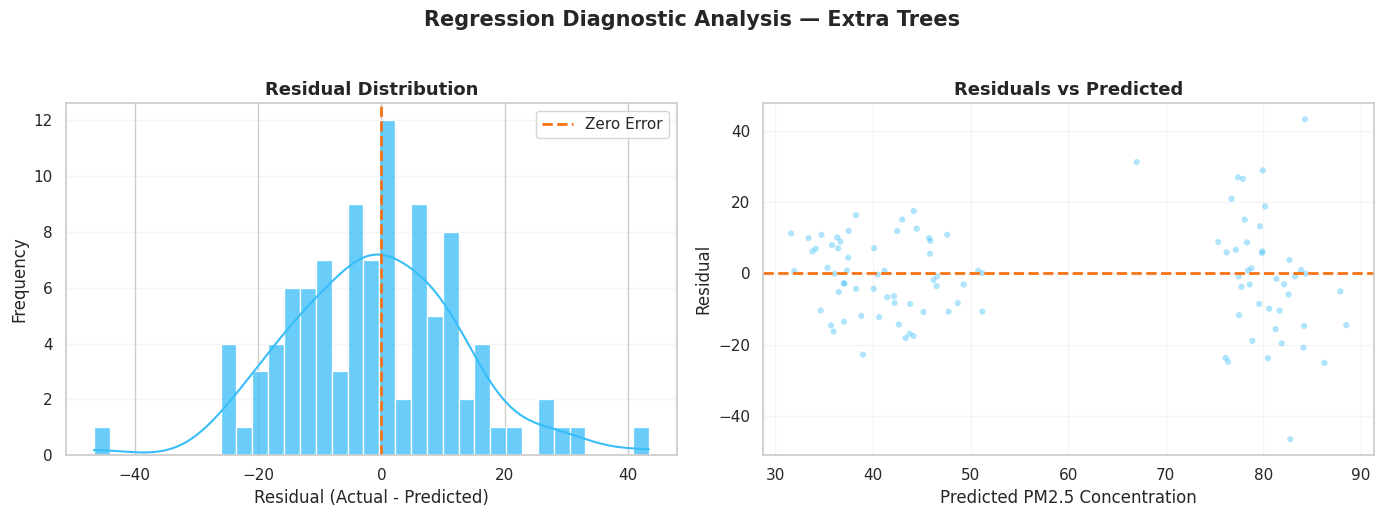

Mean Residual: -0.9091
Residual Std: 13.9154


In [43]:
# Regression Residual Analysis

resid = np.asarray(y_test_reg) - np.asarray(best_reg_pred)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Residual Distribution
sns.histplot(
    resid,
    bins=35,
    kde=True,
    color="#38bdf8",
    alpha=0.75,
    ax=ax[0]
)

ax[0].axvline(
    0,
    color="#f97316",
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

ax[0].set_title("Residual Distribution", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Residual (Actual - Predicted)")
ax[0].set_ylabel("Frequency")
ax[0].legend()
ax[0].grid(axis="y", alpha=0.2)

# Residuals vs Predicted
ax[1].scatter(
    best_reg_pred,
    resid,
    alpha=0.4,
    s=20,
    color="#38bdf8",
    edgecolors="none"
)

ax[1].axhline(
    0,
    color="#f97316",
    linestyle="--",
    linewidth=2
)

ax[1].set_title("Residuals vs Predicted", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Predicted PM2.5 Concentration")
ax[1].set_ylabel("Residual")
ax[1].grid(alpha=0.2)

plt.suptitle(
    f"Regression Diagnostic Analysis — {best_reg_name}",
    fontsize=15,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()
plt.show()

print("Mean Residual:", round(resid.mean(), 4))
print("Residual Std:", round(resid.std(), 4))

## 41. Regression feature importance

,importance
CO2,0.3362
SO2,0.1973
NO2,0.1134
PM10,0.0999
CH4,0.0912
NOx,0.0551
VOCs,0.0537
CO,0.0280
Temperature,0.0253


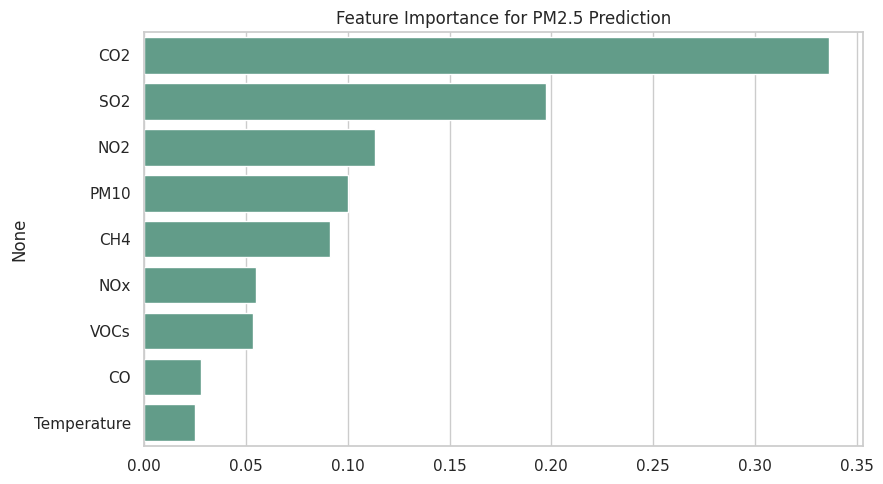

In [44]:
reg_tree = best_reg.named_steps["model"]
if hasattr(reg_tree,"feature_importances_"):
    reg_imp = pd.Series(reg_tree.feature_importances_,index=reg_features).sort_values(ascending=False).head(15)
    display(reg_imp.to_frame("importance").round(4))
    plt.figure(figsize=(9,5))
    sns.barplot(x=reg_imp.values,y=reg_imp.index,color="#59a58c")
    plt.title(f"Feature Importance for {reg_target} Prediction")
    plt.tight_layout(); plt.show()

## 42. Save fitted models and evaluation outputs

In [45]:
# Save Trained Regression Model and Outputs

import joblib
import json

# Save the best regression model
joblib.dump(best_reg, "air_quality_pollutant_regressor.joblib")

# Save regression model comparison
reg_scores.to_csv("regression_model_comparison.csv", index=False)

# Save processed dataset
df.to_csv("air_quality_cleaned_processed.csv", index=False)

# Save regression metadata
metadata = {
    "regression_target": reg_target,
    "regression_features": reg_features,
    "selected_regressor": best_reg_name,
    "regression_split": reg_split
}

with open("air_quality_model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Regression model, metrics, processed data, and metadata saved successfully.")

print("\nSaved Files:")
print("- air_quality_pollutant_regressor.joblib")
print("- regression_model_comparison.csv")
print("- air_quality_cleaned_processed.csv")
print("- air_quality_model_metadata.json")

Regression model, metrics, processed data, and metadata saved successfully.

Saved Files:
- air_quality_pollutant_regressor.joblib
- regression_model_comparison.csv
- air_quality_cleaned_processed.csv
- air_quality_model_metadata.json


## 43. Final pipeline summary

In [46]:
# Final Pipeline Summary

print("=" * 60)
print("AIR QUALITY — ML PIPELINE COMPLETE")
print("=" * 60)

print("Input file:", DATA_PATH)
print("Cleaned rows:", len(df))

print("\nREGRESSION RESULTS")
print("-" * 60)
print("Prediction target:", reg_target)
print("Train-test split:", reg_split)
print("Best model:", best_reg_name)

display(reg_scores.round(4))

print("\nSAVED FILES")
print("-" * 60)
print("- air_quality_pollutant_regressor.joblib")
print("- regression_model_comparison.csv")
print("- air_quality_cleaned_processed.csv")
print("- air_quality_model_metadata.json")

print("\nCaution: Performance reflects this dataset and its evaluation split.")
print("Validate on independent data before real-world deployment.")

print("=" * 60)

AIR QUALITY — ML PIPELINE COMPLETE
Input file: /kaggle/input/datasets/srisyra02/air-quality-dataset/air_quality_dataset.csv
Cleaned rows: 500

REGRESSION RESULTS
------------------------------------------------------------
Prediction target: PM2.5
Train-test split: random holdout
Best model: Extra Trees


,Model,MAE,RMSE,R2 Score
0,Extra Trees,10.7357,13.9450,0.6567
1,Random Forest,10.8726,14.0510,0.6514
2,Mean Baseline,19.8250,23.9488,-0.0126



SAVED FILES
------------------------------------------------------------
- air_quality_pollutant_regressor.joblib
- regression_model_comparison.csv
- air_quality_cleaned_processed.csv
- air_quality_model_metadata.json

Caution: Performance reflects this dataset and its evaluation split.
Validate on independent data before real-world deployment.
